In [2]:
%pip install numpy
%pip install pandas
%pip install seaborn
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.8 MB 2.3 MB/s eta 0:00:04
   ---- ----------------------------------- 1.0/9.8 MB 2.2 MB/s eta 0:00:04
   ------ --------------------------------- 1.6/9.8 MB 2.4 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/9.8 MB 2.5 MB/s eta 0:00:04
   ---------- ----------------------------- 2.6/9.8 MB 2.5 MB/s eta 0:00:03
   ------------- -------------------------- 3.4/9.8 MB 2.7 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.8 MB 2.7 MB/s eta 0:00:03
   ------------------- -------------------- 4.7/9.8 MB 2.8 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.8 MB 2.9 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.8 MB 3.0 MB/s eta 0:00:02
   ---------------------------- ----

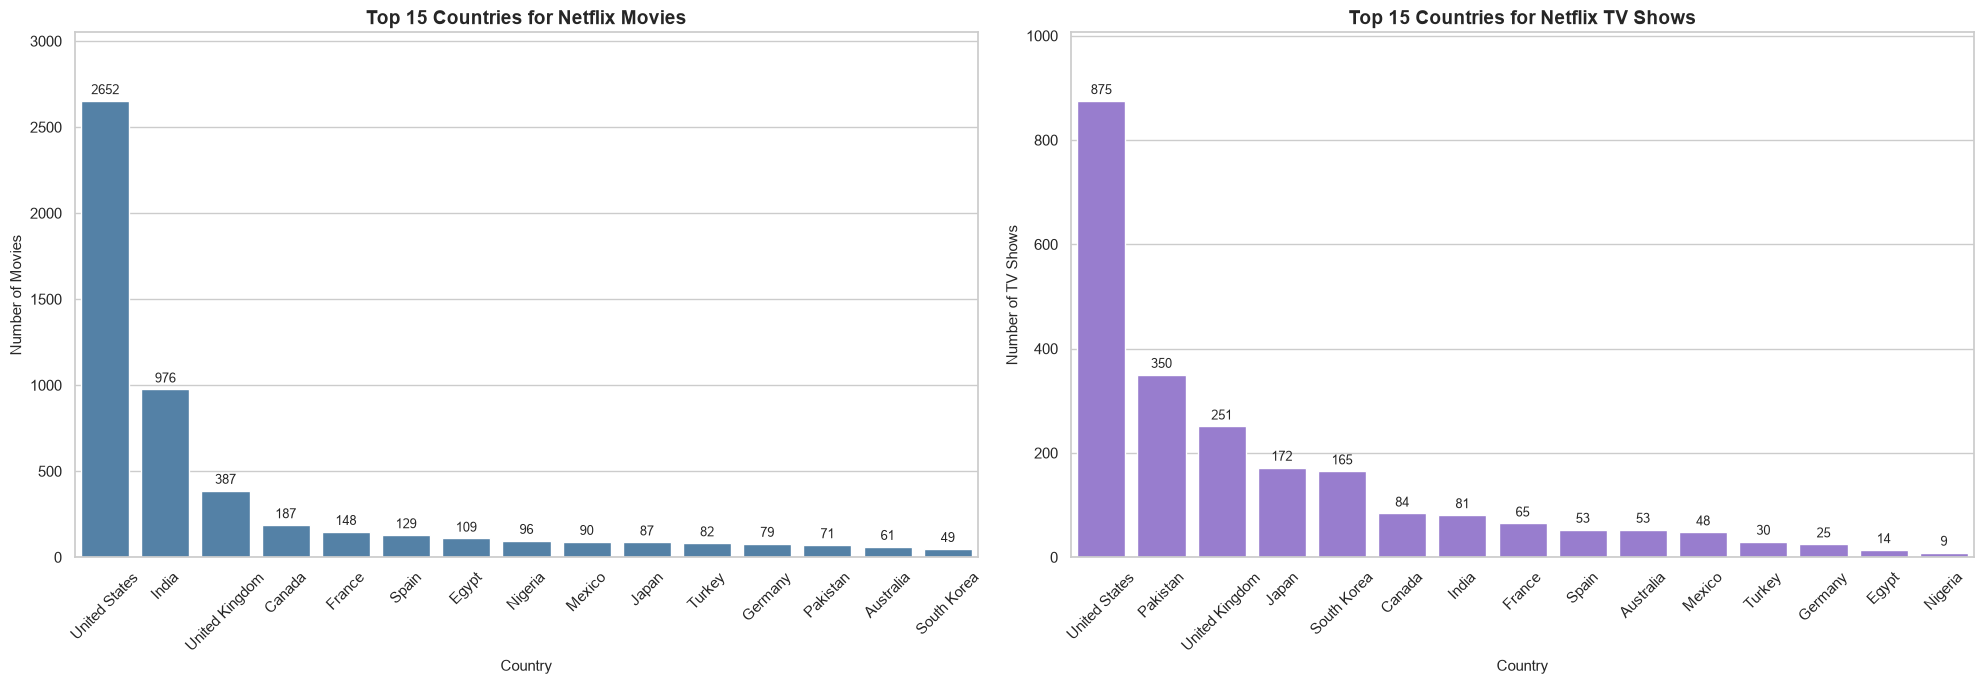

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# analysis by country column
data = pd.read_csv('Cleaned_Dataset.csv')

data['Country'] = data['Country'].str.split(',')
data = data.explode('Country')

data['Country'] = data['Country'].str.strip()

country_counts = data['Country'].value_counts().reset_index()
country_counts.columns = ['Country', 'Total_Content']

top_ten_country = country_counts.head(15)

top_list = top_ten_country['Country'].tolist()
df_top15 = data[data['Country'].isin(top_list)]
country_type = df_top15.groupby(['Country', 'Type']).size().reset_index(name='Count')

top_countries_list = top_ten_country['Country'].tolist()
df_top15 = data[data['Country'].isin(top_countries_list)]


country_type = df_top15.groupby(['Country', 'Type']).size().reset_index(name='Count')


# viualization
movies_data = country_type[country_type['Type'] == 'Movie'].sort_values(by='Count', ascending=False).head(15)
tv_shows_data = country_type[country_type['Type'] == 'Tv Show'].sort_values(by='Count', ascending=False).head(15)

sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 7))

sns.barplot(data=movies_data, x='Country', y='Count', color='steelblue', ax=axes[0])

axes[0].set_title('Top 15 Countries for Netflix Movies', fontsize=14, fontweight='bold')

axes[0].set_xlabel('Country', fontsize=11)
axes[0].set_ylabel('Number of Movies', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

if not movies_data.empty:
    axes[0].set_ylim( 0, movies_data['Count'].max() * 1.15)

sns.barplot(data=tv_shows_data, x='Country', y='Count', color='mediumpurple', ax=axes[1])

axes[1].set_title('Top 15 Countries for Netflix TV Shows', fontsize=14, fontweight='bold')

axes[1].set_xlabel('Country', fontsize=11)
axes[1].set_ylabel('Number of TV Shows', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f', padding=3, fontsize=9)

if not tv_shows_data.empty:
    axes[1].set_ylim(0, tv_shows_data['Count'].max() * 1.15)

plt.tight_layout()
plt.show()

